# Task 2: Player Segmentation
CPE342 Karena Thailand Player Intelligence. 4-class classification, target `segment`, metric $F_1$ (macro over the 4 segments).

This notebook is the Task 2 slice of `CPE342_Master_Pipeline.ipynb`: the same cells, the same shared code in `src/` and the same cached artefacts in `outputs/`, so both produce identical predictions. It ends by writing `outputs/submission_parts/task2.csv`; `python scripts/make_submission.py` joins the five parts into `submission.csv`.

**Rules followed.** Only the provided data are used; test rows are only ever predicted; every score and decision comes from 5-fold out-of-fold validation, and the final models are retrained on Train+Val combined; models are trained from scratch; no AutoML (Optuna for tuning); no leaderboard probing.

## Table of Contents
1. [Imports & Configuration](#1)
2. [Data Loading & Overview](#2)
3. [Exploratory Data Analysis](#3)
4. [Data Preparation & Feature Engineering](#4)
5. [Model Training & Evaluation](#5)
6. [Hyperparameter Tuning](#6)
7. [Stacking Ensemble (K-Fold) & Final Decision](#7)
8. [Feature Importance Analysis](#8)
9. [Submission](#9)
10. [Conclusion](#10)

<a id="1"></a>
# 1. Imports & Configuration

Global seeds, warning suppression, GPU discovery, and the exact competition metric, checked on toy inputs.

In [1]:
import os, sys, json, time, warnings, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src").exists():          # notebook lives in taskN/; the shared code is one level up
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config as C
from src.config import SEED, N_FOLDS, FBETA_AVERAGE
from src.utils import seed_everything, quiet, reduce_mem_usage, timer, save_preds, load_preds, load_params
from src.metrics import (fbeta, f2, f3, macro_f1, nmae, optimize_threshold, threshold_curve,
                         optimize_class_weights, apply_class_weights)
from src.modeling import make_folds, run_cv, run_cv_sklearn
from src import viz
from src.viz import CAT, SEQ_CMAP, DIV_CMAP, MUTED, savefig

quiet()
seed_everything(SEED)
viz.set_theme()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

import torch, lightgbm, xgboost, catboost, sklearn, optuna
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | lightgbm {lightgbm.__version__} | "
      f"xgboost {xgboost.__version__} | catboost {catboost.__version__} | sklearn {sklearn.__version__} | optuna {optuna.__version__}")
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
AVG_NAME = "positive-class" if FBETA_AVERAGE == "binary" else "macro"
print(f"SEED={SEED}  N_FOLDS={N_FOLDS}  FBETA_AVERAGE={FBETA_AVERAGE!r}")

# Execution switches: heavy artifacts are cached in outputs/ and re-used unless forced.
RUN_OPTUNA = False          # True -> (re)run Optuna studies in-notebook (slow); False -> load stored studies
RUN_T4_TRAINING = False     # True -> launch the Task 4 GPU K-fold fine-tuning if fold caches are missing

python 3.14.6 | torch 2.14.1+cu130 | lightgbm 4.7.0 | xgboost 3.4.1 | catboost 1.2.10 | sklearn 1.9.1 | optuna 5.0.0
device: cuda | NVIDIA GeForce RTX 4070 Laptop GPU
SEED=42  N_FOLDS=5  FBETA_AVERAGE='binary'


In [2]:
# Sanity-check the metric implementations on toy inputs
y_t = np.array([1, 1, 1, 0, 0, 0, 0, 0])
y_p = np.array([1, 1, 0, 1, 0, 0, 0, 0])
P, R = 2 / 3, 2 / 3
assert abs(fbeta(y_t, y_p, 2, "binary") - 5 * P * R / (4 * P + R)) < 1e-12
assert abs(fbeta(y_t, y_p, 3, "binary") - 10 * P * R / (9 * P + R)) < 1e-12
assert abs(nmae([0, 10, 30], [5, 10, 20]) - 1 / (1 + 15 / 40)) < 1e-12
print("metric checks passed | macro-F2 toy:", round(f2(y_t, y_p, 'macro'), 4), "| binary-F2 toy:", round(f2(y_t, y_p, 'binary'), 4))

metric checks passed | macro-F2 toy: 0.7333 | binary-F2 toy: 0.6667


<a id="2"></a>
# 2. Data Loading & Overview

Row *i* of `test.csv` maps positionally to submission id `ANS{i:05d}` (25,889 rows).

**Data card.**
* **Task 2** has 34 numeric plus 10 categorical features. The datacard itself flags `random_metric_1..3` as pure noise. Several tier columns are ordinal.

In [3]:
from src import task2
t2_train, t2_test = task2.load()
reduce_mem_usage(t2_train, verbose=True)
seg_names = ["Casual", "Grinder", "Social", "Whale"]
display(pd.DataFrame({"train rows": [len(t2_train)], "test rows": [len(t2_test)], "features": [t2_test.shape[1] - 1],
                      "missing rate": [t2_train.drop(columns="segment").isna().mean().mean()]}))

memory 84.4 MB -> 70.6 MB (16% saved)


,train rows,test rows,features,missing rate
0,104000,25889,44,0.0844


<a id="3"></a>
# 3. Exploratory Data Analysis

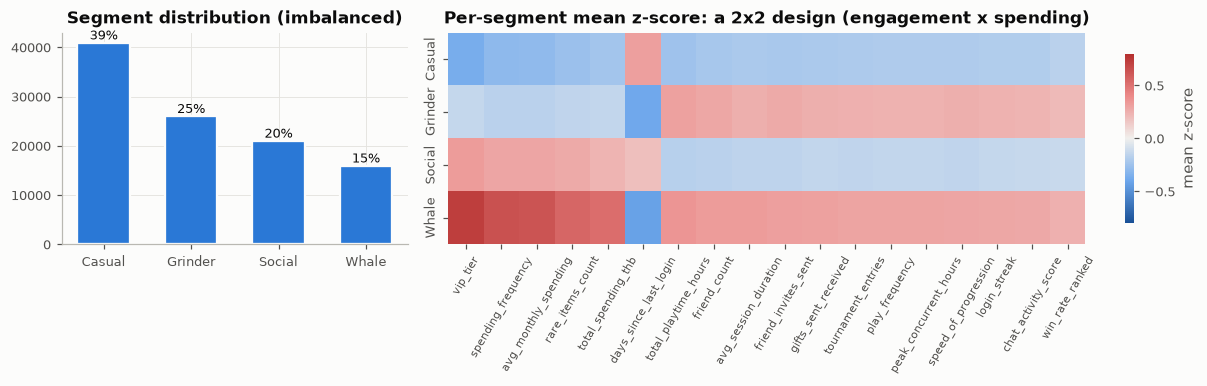

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1, 2.3]})
seg_names = ["Casual", "Grinder", "Social", "Whale"]
vc = t2_train.segment.value_counts().sort_index()
axes[0].bar(seg_names, vc.values, color=CAT[0], width=0.6, **viz.bar_gap())
for i, v in enumerate(vc.values):
    axes[0].text(i, v, f"{v / vc.sum():.0%}", ha="center", va="bottom", fontsize=8.5)
axes[0].set_title("Segment distribution (imbalanced)")

num2 = t2_train.select_dtypes("number").drop(columns=["segment"])
zmed = ((t2_train.groupby("segment")[num2.columns].mean() - num2.mean()) / num2.std()).T
zmed.columns = seg_names
zmed = zmed.loc[zmed.abs().max(axis=1).sort_values(ascending=False).index[:18]]
sns.heatmap(zmed.T, cmap=DIV_CMAP, center=0, vmin=-0.8, vmax=0.8, ax=axes[1], cbar_kws={"shrink": 0.8, "label": "mean z-score"})
axes[1].set_title("Per-segment mean z-score: a 2x2 design (engagement x spending)")
axes[1].tick_params(axis="x", labelsize=7, rotation=60)
plt.tight_layout(); savefig(fig, "t2_eda_profile"); plt.show()

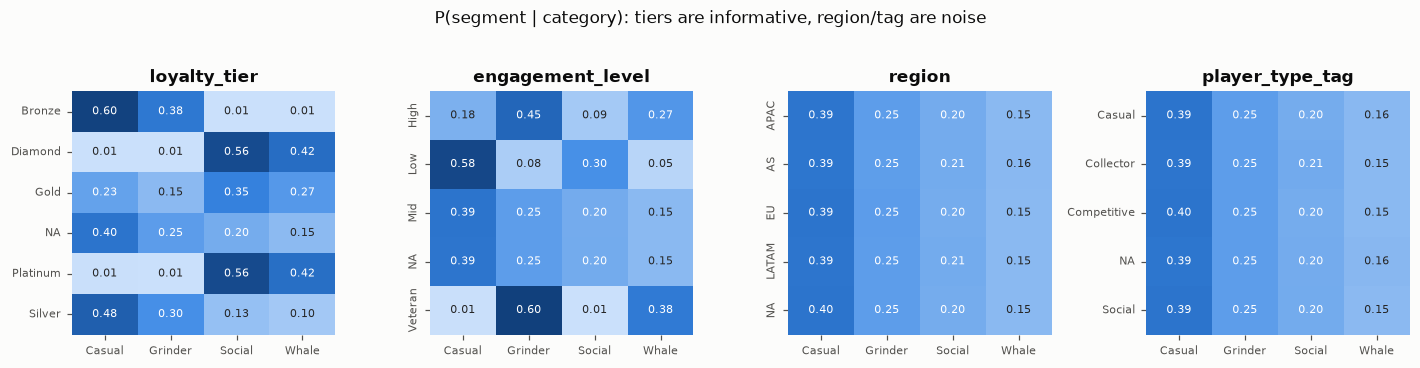

In [5]:
cats = ["loyalty_tier", "engagement_level", "region", "player_type_tag"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, c in zip(axes, cats):
    ct = pd.crosstab(t2_train[c].fillna("NA"), t2_train.segment, normalize="index")
    ct.columns = seg_names
    sns.heatmap(ct, cmap=SEQ_CMAP, vmin=0, vmax=0.65, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar=False, ax=ax)
    ax.set_title(c); ax.set_ylabel(""); ax.tick_params(labelsize=7.5)
fig.suptitle("P(segment | category): tiers are informative, region/tag are noise", y=1.03, fontsize=11)
plt.tight_layout(); savefig(fig, "t2_eda_cats"); plt.show()

**Findings.** The four segments sit on a clean **2×2 latent design**:

| | low spending | high spending |
|---|---|---|
| **low engagement** | Casual (0) | Social (2) |
| **high engagement** | Grinder (1) | Whale (3) |

Engagement is carried by many weak indicators (play frequency, session length, streaks, friends, chat, tournaments, peak hours), and spending by another set (total and monthly spend, purchase frequency, rare items, VIP, loyalty tier). `loyalty_tier` and `engagement_level` are strong ordinal proxies. `region`, `platform`, `device_type`, `payment_method`, `language`, `account_status` and `player_type_tag` show flat conditional distributions, i.e. no signal. The `random_metric_*` columns are documented noise.

*Data-quality note:* `region` shows 26% missing values versus about 8% elsewhere. pandas' default `na_values` parse the region code **"NA" (North America)** as missing, so that bucket merges North America with genuinely missing rows. It is harmless here because region carries no signal. In production, read that column with `keep_default_na=False`.

### Data-quality audit
Adversarial validation (train vs test), missing values vs target, impossible values, duplicates and collinearity, computed by `src/audit.py` on features only (see the master notebook §3.6).

In [6]:
from src import audit
with pd.option_context("display.max_colwidth", 120):
    display(pd.Series(audit.task_audit(t2_train, t2_test, "segment"), name="Task 2").to_frame())

,Task 2
train-vs-test AUC: all features,0.4990
train-vs-test AUC: missing indicators only,0.5040
train-vs-test AUC: values (missing filled by train median),0.5020
largest value shift (KS),0.0090
missing rate train / test,0.086 / 0.086
informative missing columns (p < 0.001),0 of 44
physical issues,"team_play_percentage: 1.2% of values exactly at the min (5), i.e. clipped; ranked_participation_rate: 4.8% of values..."
duplicate test rows,0
duplicate train rows,0
test rows equal to a train row,0


**Audit findings.**
* **Tasks 2 and 3:** train and test are indistinguishable (AUC 0.50), with the same missing rates. There is nothing to correct.
* **Missing values in Tasks 1–3:** no column is informative at p < 0.001. The cells are missing completely at random.
* **Impossible values:** none need cleaning. No percentage leaves [0, 100]. Several bounded scores are clipped at their limits (e.g. 8% of `aiming_smoothness` = 1 in Task 1), which trees handle. `account_age_days = 999` in Tasks 2/3 is not a sentinel: neighbouring values are just as frequent.
* **Duplicates / collinearity:** no duplicate rows within or across splits and no constant columns. The only collinear pairs are known structure: historical vs previous-month spending (Task 3, ratio 0.30–0.40) and the per-period location and skill-rating series (Task 5).

<a id="4"></a>
# 4. Data Preparation & Feature Engineering

## 4.2 Task 2: latent-factor indices, ratios and encodings
* **Noise removal:** drop `random_metric_1..3`.
* **Ordinal encoding:** `engagement_level` (Low→Veteran), `loyalty_tier` and `skill_tier` (Bronze→Diamond).
* **Composite indices:** NaN-aware means of z-scored indicators give `engagement_index` and `spending_index` (plus their product and difference). Averaging ~15 noisy, partly-missing measurements of the same latent factor removes most of the noise, which trees cannot do on their own.
* **Behavioural ratios:** `spend_per_session = total_spending_thb / (play_frequency · avg_session_duration)`, `social_engagement = friend_count / play_frequency`, `monetization_velocity = avg_monthly_spending · spending_frequency`, and others.
* **Nominal categoricals:** frequency encoding, plus **leakage-free K-fold target encoding**. Per-class rates are smoothed toward the prior, $\hat p_{c,k} = \frac{\sum_{i \in c} 1[y_i=k] + m\,\pi_k}{n_c + m}$, and fitted inside every CV fold through `task2.te_fold_fn`.

Task 2 matrix: (104000, 63) | categorical (native): ['region', 'platform', 'device_type', 'payment_method', 'language', 'account_status', 'player_type_tag']


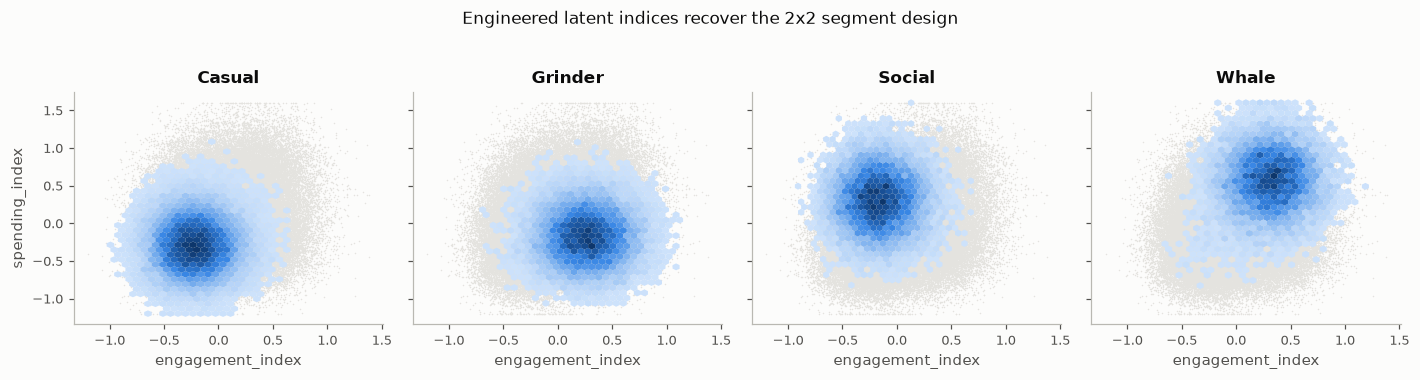

In [7]:
X2, y2, X2_test = task2.build(t2_train, t2_test)
cat2 = [c for c in X2.columns if str(X2[c].dtype) == "category"]
print(f"Task 2 matrix: {X2.shape} | categorical (native): {cat2}")
fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), sharex=True, sharey=True)
xs, ys = X2.engagement_index.clip(-1.2, 1.4), X2.spending_index.clip(-1.2, 1.6)
for k, ax in enumerate(axes):
    ax.scatter(xs, ys, s=1, color="#e4e3df", rasterized=True)
    m = y2 == k
    ax.hexbin(xs[m], ys[m], gridsize=35, cmap=SEQ_CMAP, mincnt=3)
    ax.set_title(seg_names[k]); ax.set_xlabel("engagement_index"); ax.grid(False)
axes[0].set_ylabel("spending_index")
fig.suptitle("Engineered latent indices recover the 2x2 segment design", y=1.03, fontsize=11)
plt.tight_layout(); savefig(fig, "t2_fe_latent"); plt.show()

<a id="5"></a>
# 5. Model Training & Evaluation

**Validation protocol.** 5 folds (seed 42), `StratifiedKFold` on the segment. Every model produces out-of-fold (OOF) predictions for every training row: they give honest scores, feed threshold/weight tuning and serve as stacking inputs. Test predictions average the 5 fold models. Results are cached in `outputs/preds/*.npz`; delete a file to retrain that model.

In [8]:
from sklearn.metrics import roc_auc_score, confusion_matrix, f1_score
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer

folds2 = make_folds(y2)
print("fold sizes:", [len(v) for _, v in folds2])

def cached(name, fn, force=False):
    # Return {'oof','test',...} arrays, training via fn() only when no cache exists.
    r = load_preds(name)
    if r is None or force:
        t0 = time.time()
        out = fn()
        r = {k: np.asarray(v) for k, v in out.items() if k in ("oof", "test", "p_oof", "mu_oof", "p_test", "mu_test", "sigma", "smear", "n_iter")}
        save_preds(name, **r)
        print(f"  trained {name} in {time.time() - t0:.0f}s")
    return r

BASE = {"learning_rate": 0.05}
summary = []   # running scoreboard

fold sizes: [20800, 20800, 20800, 20800, 20800]


### 5.1 Baseline and feature-engineering ablation (default LightGBM)

In [9]:
raw2 = [c for c in X2.columns if c in t2_train.columns]                     # original columns, noise removed
b = {}
b["T2 raw"] = cached("t2_base_raw", lambda: run_cv("lgb", "multiclass", BASE, X2[raw2], y2, X2_test[raw2], folds2, n_classes=4, name="T2 raw"))
b["T2 FE"] = cached("t2_base_fe", lambda: run_cv("lgb", "multiclass", BASE, X2, y2, X2_test, folds2, n_classes=4, name="T2 FE"))
b["T2 FE+TE"] = cached("t2_base_fe_te", lambda: run_cv("lgb", "multiclass", BASE, X2, y2, X2_test, folds2, n_classes=4,
                                                       fold_fn=task2.te_fold_fn, name="T2 FE+TE"))
display(pd.DataFrame([[k, "macro-F1 (argmax)", macro_f1(y2, b[k]["oof"].argmax(1))] for k in b], columns=["experiment", "metric", "OOF score"]))

,experiment,metric,OOF score
0,T2 raw,macro-F1 (argmax),0.7494
1,T2 FE,macro-F1 (argmax),0.7549
2,T2 FE+TE,macro-F1 (argmax),0.7549


**Reading the ablation**

* **Task 2:** the latent-factor indices give a clear macro-F1 gain. Leakage-free in-fold target encoding of the nominal columns is neutral, which confirms the EDA verdict that they carry no information. The final GBDTs therefore rely on native categorical handling (CatBoost's ordered target statistics are themselves a leakage-free target encoding) instead of explicit TE columns.

<a id="6"></a>
# 6. Hyperparameter Tuning

Optuna's multivariate **Tree-structured Parzen Estimator** (Bayesian optimisation) searches each model's space, and each trial is scored with the task's **exact** metric on 3-fold OOF predictions:

* **Task 2:** macro-$F_1$ of the argmax.

Studies run from `scripts/tune.py` (via `scripts/run_tuning.sh`) and persist in `outputs/optuna.db`. This section loads them, and runs them first if `RUN_OPTUNA=True`. Final models use the tuned parameters with **half the tuned learning rate** (early stopping then finds proportionally more trees), which usually adds a little accuracy at no tuning cost.

In [10]:
STORAGE = f"sqlite:///{(C.OUT / 'optuna.db').as_posix()}"
optuna.logging.set_verbosity(optuna.logging.WARNING)
STUDIES = [(2, "lgb", 15)]   # LightGBM is the primary learner; XGB/CatBoost keep robust defaults
studies, rows = {}, []
for t, m, n in STUDIES:
    name = f"task{t}_{m}"
    if RUN_OPTUNA:
        subprocess.run([sys.executable, "-u", "scripts/tune.py", "--task", str(t), "--model", m, "--trials", str(n)], check=True)
    try:
        st = optuna.load_study(study_name=name, storage=STORAGE)
    except KeyError:
        st = None
    studies[name] = st
    if st is not None and len(st.trials):
        done = [tr for tr in st.trials if tr.state.name == "COMPLETE"]
        rows.append([name, len(done), st.best_value, done[0].value, json.dumps({k: (round(v, 4) if isinstance(v, float) else v) for k, v in st.best_params.items()})])
display(pd.DataFrame(rows, columns=["study", "trials", "best OOF score", "first-trial score", "best params"]))

,study,trials,best OOF score,first-trial score,best params
0,task2_lgb,15,0.7536,0.7504,"{""learning_rate"": 0.0588, ""num_leaves"": 35, ""m..."


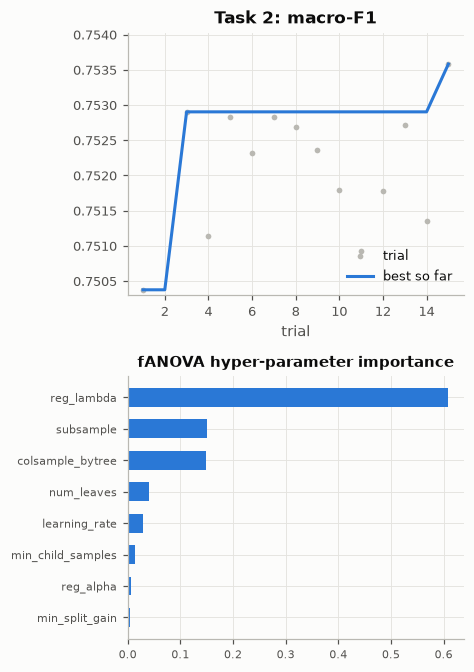

In [11]:
lgb_studies = [s for s in ("task2_lgb",) if studies.get(s) is not None]
fig, axes = plt.subplots(2, len(lgb_studies), figsize=(4.4 * len(lgb_studies), 6.2), squeeze=False)
labels = {"task1_lgb": "Task 1: F2 (study objective: macro)", "task2_lgb": "Task 2: macro-F1", "task3_lgb": "Task 3: NMAE"}
for j, s in enumerate(lgb_studies):
    df = studies[s].trials_dataframe().query("state == 'COMPLETE'")
    ax = axes[0, j]
    ax.scatter(df.number, df.value, s=14, color=MUTED, label="trial")
    ax.plot(df.number, df.value.cummax(), color=CAT[0], lw=2, label="best so far")
    ax.set_title(labels[s]); ax.set_xlabel("trial")
    lo = df.value.quantile(0.1); ax.set_ylim(lo - (df.value.max() - lo) * 0.1, df.value.max() + (df.value.max() - lo) * 0.15)
    imp = optuna.importance.get_param_importances(studies[s])
    imp = pd.Series(imp).sort_values()
    axes[1, j].barh(imp.index, imp.values, color=CAT[0], height=0.6)
    axes[1, j].set_title("fANOVA hyper-parameter importance", fontsize=10); axes[1, j].tick_params(labelsize=7.5)
axes[0, 0].legend(loc="lower right")
plt.tight_layout(); savefig(fig, "optuna"); plt.show()

In [12]:
def tuned(name, fallback):
    p = load_params(name)                                   # written when a study completes
    if p is None and studies.get(name) is not None and len(studies[name].trials):
        p = studies[name].best_params                       # partially-run study: best trial so far
    p = dict(fallback) if p is None else dict(p)
    if "learning_rate" in p:
        p["learning_rate"] = p["learning_rate"] / 2      # finer steps for the final fit
    return p


P2_lgb = tuned("task2_lgb", {"learning_rate": 0.05})
P2_cat = tuned("task2_cat", {"learning_rate": 0.08, "depth": 6})
P2_xgb = {"learning_rate": 0.04, "max_depth": 5, "min_child_weight": 10, "subsample": 0.8, "colsample_bytree": 0.5}
shown = [("P2_lgb", P2_lgb), ("P2_cat", P2_cat), ("P2_xgb", P2_xgb)]
for name, v in shown:
    print(f"{name}: {json.dumps({a: (round(b, 4) if isinstance(b, float) else b) for a, b in v.items()})}")

P2_lgb: {"learning_rate": 0.0294, "num_leaves": 35, "min_child_samples": 325, "colsample_bytree": 0.5652, "subsample": 0.8496, "reg_alpha": 0.1852, "reg_lambda": 0.0139, "min_split_gain": 0.3573}
P2_cat: {"learning_rate": 0.04, "depth": 6}
P2_xgb: {"learning_rate": 0.04, "max_depth": 5, "min_child_weight": 10, "subsample": 0.8, "colsample_bytree": 0.5}


<a id="7"></a>
# 7. Stacking Ensemble (K-Fold) & Final Decision

**Level 1:** three GBDTs with different tree-growth biases (LightGBM leaf-wise, XGBoost depth-wise, CatBoost oblivious trees with native categoricals) and a multinomial logistic regression on Gaussian-rank features, all on identical folds. **Level 2:** a regularised multinomial logistic-regression stacker on the level-1 OOF log-probabilities, itself cross-validated on the same folds. **Post-processing:** class-wise multipliers $\hat y=\arg\max_c w_c P_{ic}$ tuned on the stacked OOF probabilities for macro-$F_1$.

## 7.2 Task 2: Player segmentation (macro-F1)

,macro-F1
model,
LightGBM,0.7559
XGBoost,0.7559
CatBoost,0.7545
LogReg,0.7435
Mean of probabilities,0.7565
LogReg stacker (OOF),0.7561
Stacker + class weights,0.7568


class-wise decision multipliers w_c: {'Casual': np.float64(0.916), 'Grinder': np.float64(0.995), 'Social': np.float64(0.95), 'Whale': np.float64(1.139)}


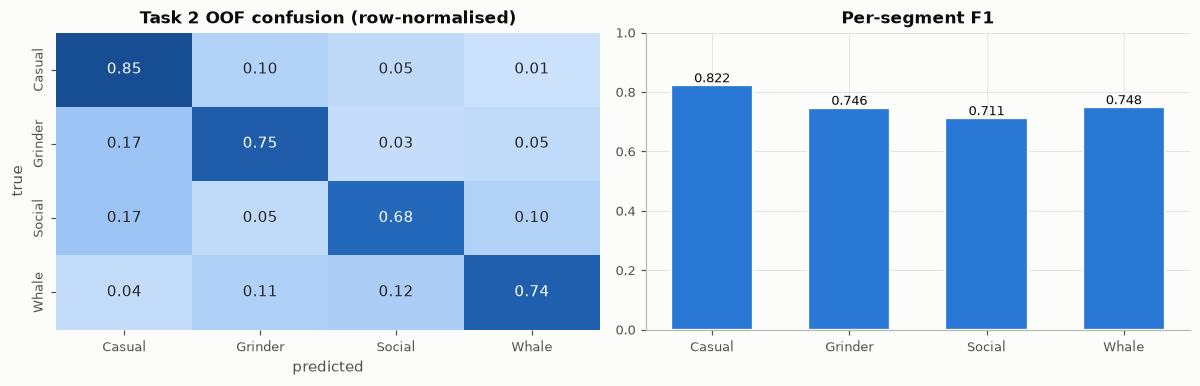

In [13]:
num2 = [c for c in X2.columns if c not in cat2]           # sklearn models: numeric columns only
m2 = {}
m2["LightGBM"] = cached("t2_lgb", lambda: run_cv("lgb", "multiclass", P2_lgb, X2, y2, X2_test, folds2, n_classes=4, name="T2 lgb"))
m2["XGBoost"] = cached("t2_xgb", lambda: run_cv("xgb", "multiclass", P2_xgb, X2, y2, X2_test, folds2, n_classes=4, name="T2 xgb"))
m2["CatBoost"] = cached("t2_cat", lambda: run_cv("cat", "multiclass", P2_cat, X2, y2, X2_test, folds2, cat_cols=cat2, n_classes=4, name="T2 cat"))
make_lr2 = lambda: make_pipeline(SimpleImputer(strategy="median"), QuantileTransformer(output_distribution="normal", random_state=SEED),
                                 LogisticRegression(C=0.5, max_iter=3000))
m2["LogReg"] = cached("t2_lr", lambda: run_cv_sklearn(make_lr2, "multiclass", X2[num2].values, y2, X2_test[num2].values,
                                                      folds2, n_classes=4, name="T2 logreg"))

def stack_multi(models, y, folds, C_=0.5):
    S = np.column_stack([np.log(np.clip(m["oof"], 1e-6, 1)) for m in models.values()])
    St = np.column_stack([np.log(np.clip(m["test"], 1e-6, 1)) for m in models.values()])
    oof = np.zeros((len(y), 4))
    for tr, va in folds:
        oof[va] = LogisticRegression(C=C_, max_iter=3000).fit(S[tr], y[tr]).predict_proba(S[va])
    final = LogisticRegression(C=C_, max_iter=3000).fit(S, y)
    return oof, final.predict_proba(St), final

stack2_oof, stack2_test, STACKER2 = stack_multi(m2, y2, folds2)
W2, SCORE2 = optimize_class_weights(y2, stack2_oof)
rows = [[k, macro_f1(y2, v["oof"].argmax(1))] for k, v in m2.items()]
rows += [["Mean of probabilities", macro_f1(y2, np.mean([v["oof"] for v in m2.values()], 0).argmax(1))],
         ["LogReg stacker (OOF)", macro_f1(y2, stack2_oof.argmax(1))],
         ["Stacker + class weights", SCORE2]]
display(pd.DataFrame(rows, columns=["model", "macro-F1"]).set_index("model").style.format("{:.4f}").highlight_max(props="font-weight:bold"))
print("class-wise decision multipliers w_c:", dict(zip(seg_names, np.round(W2, 3))))
pred2 = apply_class_weights(stack2_test, W2)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
cm = confusion_matrix(y2, apply_class_weights(stack2_oof, W2), normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap=SEQ_CMAP, vmin=0, vmax=1, xticklabels=seg_names, yticklabels=seg_names, cbar=False, ax=axes[0])
axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true"); axes[0].set_title("Task 2 OOF confusion (row-normalised)")
per_cls = f1_score(y2, apply_class_weights(stack2_oof, W2), average=None)
axes[1].bar(seg_names, per_cls, color=CAT[0], width=0.6, **viz.bar_gap())
for i, v in enumerate(per_cls):
    axes[1].text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8.5)
axes[1].set_ylim(0, 1); axes[1].set_title("Per-segment F1")
plt.tight_layout(); savefig(fig, "t2_confusion"); plt.show()
summary.append(["Task 2", "macro-F1", SCORE2, "4 L1 models -> multinomial stacker -> class multipliers"])

The confusion matrix mirrors the 2×2 design. Almost all errors fall between segments that differ in **only one** latent factor:
* Grinder→Casual and Whale→Social sit on the engagement axis.
* Social→Casual and Whale→Grinder sit on the spending axis.

Two-factor mistakes (Casual↔Whale, Grinder↔Social) are rare. The class multipliers slightly up-weight Social and Whale, trading a little Casual precision for minority-class recall, which is exactly what macro-F1 rewards.

## 7.6 Final model: combine Train+Val (competition rule)
The rules say: *"Combine Train+Val for training"* and *"✅ Allowed: combining Train and Validation sets for final model training after all validation is complete."* Everything above was validation: the 5-fold OOF predictions are what we scored, tuned and stacked on. Each fold model saw only 80% of the labelled data. Now, with every decision fixed, each level-1 model is **retrained once on 100% of the labelled rows**:

* **GBDTs:** the validated hyper-parameters are reused. The number of boosting rounds comes from early stopping on fold 0, ×1.15 for the 25% larger training set, so no hold-out is needed.
* **ExtraTrees / logistic regression / hurdle stages:** refitted on all rows.

The final level-1 test input is the **average of the 5-fold models and the full-data model**. Both are legitimate final models, and averaging them lowers variance. **Nothing is re-tuned:** the stacker, the threshold τ, the class multipliers, the L1 blend weights, the zero gate and the scale all keep their out-of-fold values. Task 5 has no labelled data, so its detectors are already fitted on all available data.

In [14]:
from src.modeling import refit_full, refit_full_sklearn
FULL_W = 0.5                                     # weight of the full-data model in the final test input
blend_full = lambda fold_test, full_test: (1 - FULL_W) * np.asarray(fold_test) + FULL_W * np.asarray(full_test)
changes = []

# ---- Task 2
f2m = {}
f2m["LightGBM"] = cached("t2_lgb_full", lambda: refit_full("lgb", "multiclass", P2_lgb, X2, y2, X2_test, folds2, name="T2 lgb"))
f2m["XGBoost"] = cached("t2_xgb_full", lambda: refit_full("xgb", "multiclass", P2_xgb, X2, y2, X2_test, folds2, name="T2 xgb"))
f2m["CatBoost"] = cached("t2_cat_full", lambda: refit_full("cat", "multiclass", P2_cat, X2, y2, X2_test, folds2, cat_cols=cat2, name="T2 cat"))
f2m["LogReg"] = cached("t2_lr_full", lambda: refit_full_sklearn(make_lr2, "multiclass", X2[num2].values, y2, X2_test[num2].values))
St2 = np.column_stack([np.log(np.clip(blend_full(m2[k]["test"], f2m[k]["test"]), 1e-6, 1)) for k in m2])
pred2_final = apply_class_weights(STACKER2.predict_proba(St2), W2)
changes.append(["Task 2", "labels changed", np.mean(pred2_final != pred2), ""])

display(pd.DataFrame(changes, columns=["task", "check", "value", "note"]).set_index("task").round(4))
pred2 = pred2_final   # used by section 9

,check,value,note
task,,,
Task 2,labels changed,0.0048,


<a id="8"></a>
# 8. Feature Importance Analysis

Exact **TreeSHAP** (Lundberg & Lee) values come from a LightGBM model refit on fold 0 with the tuned parameters, explaining 4,000 held-out rows.

In [15]:
import lightgbm as lgb
from sklearn.inspection import permutation_importance

def fold0_lgb(params, X, y, objective, n_classes=None):
    tr, va = (folds1 if objective == "binary" else folds2 if objective == "multiclass" else folds3)[0]
    from src.modeling import LGB_BASE
    p = {**LGB_BASE, **params, "objective": {"binary": "binary", "multiclass": "multiclass", "regression": "regression_l1"}[objective]}
    Model = lgb.LGBMRegressor if objective == "regression" else lgb.LGBMClassifier
    m = Model(**p).fit(X.iloc[tr], y[tr], eval_set=[(X.iloc[va], y[va])], callbacks=[lgb.early_stopping(200, verbose=False)])
    return m, va

def tree_shap(model, Xs):
    # LightGBM's built-in TreeSHAP (pred_contrib) - exact, handles categoricals; drops the bias column
    c = model.booster_.predict(Xs, pred_contrib=True, num_iteration=model.best_iteration_)
    k = Xs.shape[1] + 1
    return c.reshape(len(Xs), -1, k)[:, :, :-1] if c.shape[1] > k else c[:, :-1]

def shap_panel(ax, sv, Xs, title, top=14):
    imp = pd.Series(np.abs(sv).mean(0), index=Xs.columns).sort_values().tail(top)
    ax.barh(imp.index, imp.values, color=CAT[0], height=0.65)
    ax.set_title(title); ax.set_xlabel("mean |SHAP|"); ax.tick_params(axis="y", labelsize=8)
    return imp

def dependence(ax, sv, Xs, col, color=CAT[0]):
    j = list(Xs.columns).index(col)
    x = Xs[col].values
    lo, hi = np.nanpercentile(x, [0.5, 99.5])
    m = ~np.isnan(x) & (x >= lo) & (x <= hi)
    ax.scatter(x[m], sv[m, j], s=3, alpha=0.35, color=color, rasterized=True)
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_xlabel(col); ax.set_ylabel("SHAP value")

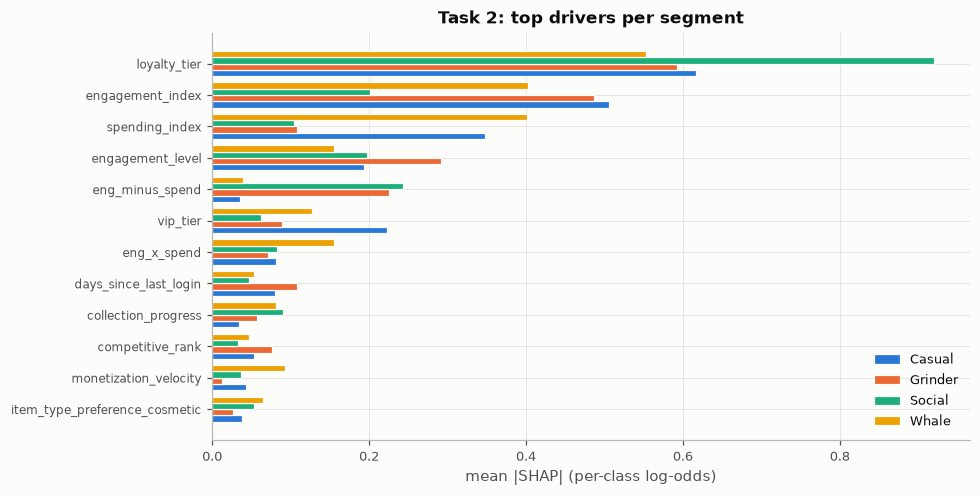

In [16]:
mdl2, va2 = fold0_lgb(P2_lgb, X2, y2, "multiclass")
Xs2 = X2.iloc[va2].sample(4000, random_state=SEED)
sv2 = tree_shap(mdl2, Xs2)                     # (n, k, f)
if sv2.ndim == 3 and sv2.shape[1] == 4:
    per_class = pd.DataFrame({seg_names[k]: np.abs(sv2[:, k, :]).mean(0) for k in range(4)}, index=Xs2.columns)
else:
    per_class = pd.DataFrame({seg_names[k]: np.abs(sv2[..., k]).mean(0) for k in range(4)}, index=Xs2.columns)
top2 = per_class.sum(1).sort_values().tail(12).index
fig, ax = plt.subplots(figsize=(9, 4.6))
yy = np.arange(len(top2)); hgt = 0.2
for k, sname in enumerate(seg_names):
    ax.barh(yy + (k - 1.5) * hgt, per_class.loc[top2, sname], height=hgt, color=CAT[k], label=sname, edgecolor=viz.SURFACE, linewidth=0.8)
ax.set_yticks(yy); ax.set_yticklabels(top2, fontsize=8); ax.set_xlabel("mean |SHAP| (per-class log-odds)")
ax.set_title("Task 2: top drivers per segment"); ax.legend(loc="lower right")
plt.tight_layout(); savefig(fig, "t2_shap"); plt.show()

**Business reading (segmentation).** Two engineered latent indices plus `loyalty_tier` and `engagement_level` drive almost every decision. A practical consequence: **two scores per player (engagement and spending) are enough to target campaigns**.
* **Whales** (high/high) should get VIP care and exclusive bundles, *without* blanket discounts.
* **Socials** (high spending, low engagement) respond to cosmetics and social events.
* **Grinders** (high engagement, low spending) are the audience for ranked and tournament messaging.
* **Casuals** should get light-touch retention offers rather than esports promotion.

<a id="9"></a>
# 9. Submission

The Task 2 column of the submission: `task2` is a plain integer code, as defined in the datacard. The part is written to `outputs/submission_parts/task2.csv` with the `id` column of `sample_submission.csv`; `python scripts/make_submission.py` checks and joins the five parts.

In [17]:
sample_sub = pd.read_csv(C.SAMPLE_SUB)
part = pd.DataFrame({"id": sample_sub.id, "task2": pred2.astype(int)})
assert len(part) == C.N_TEST == len(t2_test) and part.id.tolist() == [f"ANS{i:05d}" for i in range(1, C.N_TEST + 1)]
assert part["task2"].notna().all() and set(part.task2.unique()) <= {0, 1, 2, 3}
part_dir = C.OUT / "submission_parts"
part_dir.mkdir(exist_ok=True)
part.to_csv(part_dir / "task2.csv", index=False)
print(f"saved {part_dir / 'task2.csv'} | {part.shape}")
display(part.head())
print("predicted segment shares:", dict(zip(seg_names, np.round(np.bincount(pred2, minlength=4) / len(pred2), 3))))

saved C:\Users\Oping\cpe342-kaggle-main\outputs\submission_parts\task2.csv | (25889, 2)


,id,task2
0,ANS00001,3
1,ANS00002,3
2,ANS00003,2
3,ANS00004,1
4,ANS00005,0


predicted segment shares: {'Casual': np.float64(0.42), 'Grinder': np.float64(0.251), 'Social': np.float64(0.181), 'Whale': np.float64(0.148)}


<a id="10"></a>
# 10. Conclusion

In [18]:
display(pd.DataFrame(summary, columns=["task", "metric", "OOF score", "final recipe"]).set_index("task").style.format({"OOF score": "{:.4f}"}))

,metric,OOF score,final recipe
task,,,
Task 2,macro-F1,0.7568,4 L1 models -> multinomial stacker -> class multipliers


| Task | Key insight | What moved the score |
|---|---|---|
| 2 Segmentation | 2×2 latent design (engagement × spending) | **Noise-averaging latent indices**, ordinal tiers; stack + **class-wise multipliers** |